In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!pip install yfinance pandas numpy lxml

In [3]:
import os, io, sys, json, shutil, warnings, subprocess, datetime as dt
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import yfinance as yf
import scipy, sklearn, matplotlib
from scipy.cluster.hierarchy import linkage, dendrogram, cophenet
from scipy.spatial.distance import pdist
from scipy.optimize import linear_sum_assignment
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA

warnings.filterwarnings("ignore")
START, END = "2021-01-01", "2025-01-01"      # END is exclusive
BENCH = "^GSPC"
SEED = 42
FORCE_DOWNLOAD = False                        # True = ignore cached csv files and re-download
BASE_DIR = os.environ.get("BASE_DIR", ".")    # e.g. "/content/drive/MyDrive/CRM_CW1" to persist on Drive
DATA_DIR = os.environ.get("DATA_DIR", os.path.join(BASE_DIR, "data"))
OUT_DIR = os.environ.get("OUT_DIR", os.path.join(BASE_DIR, "outputs"))
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)

print("Package versions:")
for m in (pd, np, yf, scipy, sklearn, matplotlib):
    print(f"  {m.__name__} {m.__version__}")
print("DATA_DIR:", os.path.abspath(DATA_DIR), "| OUT_DIR:", os.path.abspath(OUT_DIR))

Package versions:
  pandas 2.2.3
  numpy 2.4.6
  yfinance 0.2.66
  scipy 1.16.3
  sklearn 1.6.1
  matplotlib 3.10.0
DATA_DIR: /content/data | OUT_DIR: /content/outputs


# **Task 01**

1.1  Ticker list and data acquisition

In [4]:
url= "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"
tick_path = f"{DATA_DIR}/sp500_tickers.csv"
try:
    html = requests.get(url, headers={"User-Agent": "Mozilla/5.0"}, timeout=30).text
    sp = pd.read_html(io.StringIO(html))[0]
    sp["Retrieval_date"] = dt.date.today().isoformat()
    sp.to_csv(tick_path, index=False)
    print("Ticker list fetched live.")
except Exception as e:
    print("Live fetch failed, using cached ticker list:", e)
    sp = pd.read_csv(tick_path)
retrieval_date = sp["Retrieval_date"].iloc[0]
sp["yf_ticker"] = sp["Symbol"].str.replace(".", "-", regex=False)   # BRK.B -> BRK-B for Yahoo
tickers = sp["yf_ticker"].tolist()
sector_map = sp.set_index("yf_ticker")["GICS Sector"]
print(f"Ticker list retrieval date: {retrieval_date} | tickers: {len(tickers)}")


Ticker list fetched live.
Ticker list retrieval date: 2026-11-24 | tickers: 503


In [5]:
files = {"adj_close": "Adj Close", "close": "Close", "volume": "Volume"}
paths = {k: f"{DATA_DIR}/{k}.csv" for k in files}
snap_path = f"{DATA_DIR}/snapshot_info.json"

if all(os.path.exists(p) for p in paths.values()) and not FORCE_DOWNLOAD:
    adj, close, vol = [pd.read_csv(paths[k], index_col=0, parse_dates=True) for k in files]
    data_source = "cached csv snapshot"
    if os.path.exists(snap_path):
        snap = json.load(open(snap_path))
    else:   # older runs did not record the download date: fall back to the file timestamp and say so
        snap = {"download_date": dt.date.fromtimestamp(os.path.getmtime(paths["adj_close"])).isoformat(),
                "note": "inferred from file modification time (snapshot_info.json not found)"}
else:
    all_tk = tickers + [BENCH]
    frames = []
    for i in range(0, len(all_tk), 100):                    # batches to avoid rate limits
        frames.append(yf.download(all_tk[i:i + 100], start=START, end=END,
                                  auto_adjust=False, progress=False, threads=True))
    raw = pd.concat(frames, axis=1)
    raw = raw.loc[:, ~raw.columns.duplicated()]
    n_dup_dates = int(raw.index.duplicated().sum())
    print("Duplicate dates in raw download:", n_dup_dates)
    raw = raw[~raw.index.duplicated()].sort_index()
    raw.index = pd.to_datetime(raw.index).tz_localize(None)
    raw = raw.loc[(raw.index >= START) & (raw.index < END)]
    adj, close, vol = raw["Adj Close"], raw["Close"], raw["Volume"]
    for k, df in zip(files, (adj, close, vol)):
        df.to_csv(paths[k])
    data_source = "yfinance live download"
    snap = {"download_date": dt.date.today().isoformat(), "library": f"yfinance {yf.__version__}",
            "auto_adjust": False, "start": START, "end_exclusive": END}
    json.dump(snap, open(snap_path, "w"), indent=2)
snapshot_date = snap["download_date"]
print("Data source:", data_source, "| price snapshot date:", snapshot_date, "|", snap.get("note", ""))
print("Shape:", adj.shape, "| range:", adj.index.min().date(), "to", adj.index.max().date())
print("Ticker list retrieved", retrieval_date, "vs price snapshot", snapshot_date,
      "-> tickers added/removed between the two dates can appear as 'no data returned'.")

ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['FDXF']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['HONA']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['Q']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')
ERROR:yfinance:
2 Failed downloads:
ERROR:yfinance:['SNDK', 'VYLR']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


Duplicate dates in raw download: 0
Data source: yfinance live download | price snapshot date: 2026-11-24 | 
Shape: (1005, 504) | range: 2021-01-04 to 2024-12-31
Ticker list retrieved 2026-11-24 vs price snapshot 2026-11-24 -> tickers added/removed between the two dates can appear as 'no data returned'.


1.2 Validation and alignment

In [6]:
excl_log = []
def exclude(t, reason):
    excl_log.append({"ticker": t, "reason": reason})

assert adj.index.is_monotonic_increasing and not adj.index.duplicated().any()
bench_idx = adj[BENCH].dropna().index            # benchmark trading calendar
print("Benchmark trading days:", len(bench_idx))
print("Benchmark nonpositive prices:", int((adj[BENCH] <= 0).sum()))

flags = []                                       # possible corporate-action / data issues (reviewed, not auto-excluded)
for t in tickers:
    if t not in adj.columns or adj[t].isna().all():
        exclude(t, "no data returned"); continue
    a, c, v = adj[t].reindex(bench_idx), close[t].reindex(bench_idx), vol[t].reindex(bench_idx)
    n_miss = int(a.isna().sum() + c.isna().sum())
    if n_miss > 0:
        exclude(t, f"missing prices on benchmark dates ({n_miss}); unequal/short history, not filled"); continue
    if (a <= 0).any() or (c <= 0).any():
        exclude(t, "nonpositive price"); continue
    if v.isna().any() or (v < 0).any():
        exclude(t, "missing or negative volume"); continue
    # corporate action checks
    c_ret, a_ret = c.pct_change(), a.pct_change()
    big = c_ret.abs() > 0.35
    ratio_step = a.div(c).pct_change().abs() > 0.10
    zero_vol = int((v == 0).sum())
    if big.any() or ratio_step.any() or zero_vol:
        d = c_ret.abs().idxmax()
        flags.append({"ticker": t, "n_close_moves_gt35pct": int(big.sum()),
                      "largest_close_move_date": d.date(), "largest_close_move": round(float(c_ret[d]), 3),
                      "adj_move_same_day": round(float(a_ret[d]), 3),
                      "n_adj_close_ratio_steps_gt10pct": int(ratio_step.sum()), "zero_volume_days": zero_vol})

excl_df = pd.DataFrame(excl_log, columns=["ticker", "reason"])
flag_df = pd.DataFrame(flags, columns=["ticker", "n_close_moves_gt35pct", "largest_close_move_date", "largest_close_move",
                                       "adj_move_same_day", "n_adj_close_ratio_steps_gt10pct", "zero_volume_days"])
if len(flag_df):   # automatic triage so each flag has a documented decision
    flag_df["triage"] = np.where(
        (flag_df["n_close_moves_gt35pct"] > 0) & ((flag_df["largest_close_move"] - flag_df["adj_move_same_day"]).abs() < 0.05),
        "genuine price move: Close and Adj Close agree, not a split artefact; kept",
        np.where(flag_df["n_adj_close_ratio_steps_gt10pct"] > 0,
                 "adj/close ratio step (large distribution or adjustment): checked, kept",
                 "zero-volume days: kept, no effect on events/traded value unless in window"))
valid = [t for t in tickers if t not in set(excl_df["ticker"])]
print(f"Included: {len(valid)} | Excluded: {len(excl_df)}")
if len(excl_df):
    print(excl_df["reason"].str.replace(r"\(\d+\)", "(n)", regex=True).value_counts())
print("Flagged for corporate-action review (kept):", len(flag_df))
if len(flag_df):
    print(flag_df.to_string(index=False))
excl_df.to_csv(f"{OUT_DIR}/exclusion_log.csv", index=False)
flag_df.to_csv(f"{OUT_DIR}/corporate_action_flags.csv", index=False)

# Aligned daily panels on the benchmark calendar (nothing is filled)
adj_v = adj[valid].reindex(bench_idx)
close_v = close[valid].reindex(bench_idx)
vol_v = vol[valid].reindex(bench_idx)
bench_adj = adj[BENCH].reindex(bench_idx)
assert not adj_v.isna().any().any() and not close_v.isna().any().any() and not vol_v.isna().any().any()

# Yahoo 'Close' is split-adjusted but NOT dividend-adjusted; 'Adj Close' is both.
# Volume is split-adjusted, so Close x Volume is on a consistent split basis.
# Returns/beta use Adj Close for shares AND benchmark (same price basis).

Benchmark trading days: 1005
Benchmark nonpositive prices: 0
Included: 488 | Excluded: 15
reason
missing prices on benchmark dates (n); unequal/short history, not filled    10
no data returned                                                             5
Name: count, dtype: int64
Flagged for corporate-action review (kept): 10
ticker  n_close_moves_gt35pct largest_close_move_date  largest_close_move  adj_move_same_day  n_adj_close_ratio_steps_gt10pct  zero_volume_days                                                                    triage
  BIIB                      2              2022-09-28               0.399              0.399                                0                 0 genuine price move: Close and Adj Close agree, not a split artefact; kept
    BE                      2              2024-11-15               0.592              0.592                                0                 0 genuine price move: Close and Adj Close agree, not a split artefact; kept
  CVNA            

1.3 Weekly return and weekly beta

In [7]:
def weekly_last(x):
    return x.resample("W-FRI").last()       # final available trading price in each Friday-ending week

w_px = weekly_last(adj_v)
w_bm = weekly_last(bench_adj.to_frame(BENCH))[BENCH]

first_d, last_d = bench_idx[0], bench_idx[-1]
wk_end = w_px.index
complete = (wk_end - pd.Timedelta(days=4) >= first_d) & (wk_end <= last_d)     # drop incomplete first/final calendar weeks
print("Dropped weeks:", [d.date() for d in wk_end[~complete]])
w_px, w_bm = w_px[complete], w_bm[complete]

w_ret = w_px.pct_change(fill_method=None)             # P_t / P_{t-1} - 1, no filling, NaN stays NaN
b_ret = w_bm.pct_change(fill_method=None)
common_weeks = b_ret.dropna().index.intersection(w_ret.dropna(how="all").index)
w_ret, b_ret = w_ret.loc[common_weeks], b_ret.loc[common_weeks]
assert not w_ret.isna().any().any()
assert (w_ret.index == b_ret.index).all()             # identical week labels for shares and benchmark
n_weeks = len(common_weeks)
print(f"Aligned weekly return observations: {n_weeks} ({common_weeks[0].date()} to {common_weeks[-1].date()})")

mean_ret = w_ret.mean()                               # arithmetic mean weekly return
beta = w_ret.apply(lambda s: s.cov(b_ret) / b_ret.var())          # cov(share, bench) / var(bench), same ddof
# independent checks
chk = pd.Series({t: np.polyfit(b_ret.values, w_ret[t].values, 1)[0] for t in valid})
assert np.allclose(beta, chk, atol=1e-8), "beta mismatch"
ex_t = valid[0]
px = w_px[ex_t].values
manual_mean = np.mean([px[i] / px[i - 1] - 1 for i in range(1, len(px))])     # explicit loop on one share
assert np.isclose(manual_mean, mean_ret[ex_t]) and len(px) - 1 == n_weeks
# estimation uncertainty of beta (OLS standard error) for the interpretation of market sensitivity
r_xy = w_ret.apply(lambda s: s.corr(b_ret))
beta_se = np.sqrt((1 - r_xy ** 2) / (n_weeks - 2)) * w_ret.std() / b_ret.std()
print(f"Check passed for {ex_t}: manual mean {manual_mean:.5f} | beta OLS check OK for all {len(valid)} shares")
print("Median beta standard error:", round(float(beta_se.median()), 3))
print(pd.DataFrame({"mean_ret": mean_ret, "beta": beta, "beta_se": beta_se}).describe().round(5))
w_ret.to_csv(f"{OUT_DIR}/weekly_returns_shares.csv")
b_ret.rename("benchmark").to_csv(f"{OUT_DIR}/weekly_returns_benchmark.csv")

Dropped weeks: [datetime.date(2025, 1, 3)]
Aligned weekly return observations: 207 (2021-01-15 to 2024-12-27)
Check passed for MMM: manual mean 0.00114 | beta OLS check OK for all 488 shares
Median beta standard error: 0.101
        mean_ret       beta    beta_se
count  488.00000  488.00000  488.00000
mean     0.00286    0.97387    0.11244
std      0.00265    0.40655    0.04139
min     -0.00447    0.05545    0.05682
25%      0.00118    0.66663    0.08607
50%      0.00263    0.95061    0.10067
75%      0.00421    1.17929    0.12746
max      0.01777    3.77856    0.43623


1.4 Adapted RFM

In [8]:
obs_date = bench_idx[-1]            # final common completed trading date (all included shares have a price/volume here)
print("Observation date:", obs_date.date())

baseline = vol_v.shift(1).rolling(20).mean()          # preceding 20 sessions, excludes the day being tested
threshold = 2 * baseline
event = (vol_v > threshold) & threshold.notna()       # high-volume day flag per share and day

window = bench_idx[-60:]                              # latest 60 trading sessions
assert len(bench_idx) >= 80, "need 20-session baseline + 60-session window"

last_event = event.apply(lambda s: s.index[s.values].max() if s.any() else pd.NaT)
R = (obs_date - last_event).dt.days                   # calendar days; event on obs date -> 0; NaT -> NaN (no event)
F = event.loc[window].sum()
M = (close_v * vol_v).loc[window].sum()               # USD approximate traded value over the 60 sessions

rfm = pd.DataFrame({"R": R, "F": F, "M": M})
print("Shares with no event in valid history (R missing):", int(rfm["R"].isna().sum()))
print(rfm.describe().round(2))
event.loc[window].astype(int).to_csv(f"{OUT_DIR}/event_flags_last60.csv")     # reproducible event flags

Observation date: 2024-12-31
Shares with no event in valid history (R missing): 0
            R       F             M
count  488.00  488.00  4.880000e+02
mean    20.39    2.99  3.930290e+10
std     21.30    1.33  1.288833e+11
min      4.00    0.00  1.297483e+09
25%     11.00    2.00  1.023194e+10
50%     11.00    3.00  1.668382e+10
75%     15.00    4.00  3.210048e+10
max    222.00    8.00  1.847697e+12


In [9]:
# Edge-case evidence for 1.4 (checks only, no change to the calculation)
print("Shares with event on observation date (R=0):", int((rfm["R"] == 0).sum()))
print("Shares with no event (R missing):", int(rfm["R"].isna().sum()))
print("First day with a valid 20-session threshold:", threshold.dropna(how="all").index[0].date())
print("History needed (20 baseline + 60 window):", 80, "| available sessions:", len(bench_idx))
print("Shares with F = 0 in the 60-session window:", int((rfm["F"] == 0).sum()))
print("Most common R values:", rfm["R"].value_counts().head(3).to_dict(),
      "-> many shares share the same R when one market-wide high-volume day (e.g. index rebalance / options expiry) is their latest event")

# Independent loop re-calculation of R and F for EVERY included share (no pandas rolling)
win_set, bad = set(window), 0
for t in valid:
    v = vol_v[t].values
    evd = [bench_idx[i] for i in range(20, len(v)) if v[i] > 2 * v[i - 20:i].mean()]
    F_c = sum(d in win_set for d in evd)
    R_c = (obs_date - max(evd)).days if evd else np.nan
    same_R = (np.isnan(R_c) and np.isnan(rfm.loc[t, "R"])) or R_c == rfm.loc[t, "R"]
    if F_c != rfm.loc[t, "F"] or not same_R:
        bad += 1
print("Shares where loop check disagrees with vectorised R/F:", bad)
assert bad == 0

Shares with event on observation date (R=0): 0
Shares with no event (R missing): 0
First day with a valid 20-session threshold: 2021-02-02
History needed (20 baseline + 60 window): 80 | available sessions: 1005
Shares with F = 0 in the 60-session window: 10
Most common R values: {11: 354, 36: 17, 55: 11} -> many shares share the same R when one market-wide high-volume day (e.g. index rebalance / options expiry) is their latest event
Shares where loop check disagrees with vectorised R/F: 0


In [10]:
# Worked example (one share) + independent M check
ex = "AAPL" if "AAPL" in valid else valid[0]
tbl = pd.DataFrame({"Close": close_v[ex], "Volume": vol_v[ex], "Prev20_mean": baseline[ex],
                    "Threshold(2x)": threshold[ex], "HighVolDay": event[ex],
                    "TradedValue": close_v[ex] * vol_v[ex]}).loc[window]
print(f"Worked example: {ex}")
print(tbl.tail(10).round(2))
c_arr, v_arr = close_v[ex].values, vol_v[ex].values
M_chk = float((c_arr[-60:] * v_arr[-60:]).sum())
print(f"R={rfm.loc[ex,'R']} | F={rfm.loc[ex,'F']} | M={rfm.loc[ex,'M']:.3e} (check {M_chk:.3e})")
assert np.isclose(rfm.loc[ex, "M"], M_chk)
tbl.to_csv(f"{OUT_DIR}/worked_example_{ex}.csv")

Worked example: AAPL
             Close     Volume  Prev20_mean  Threshold(2x)  HighVolDay  \
Date                                                                    
2024-12-17  253.48   51356400   42354720.0     84709440.0       False   
2024-12-18  248.05   56774100   42690855.0     85381710.0       False   
2024-12-19  249.79   60882300   43718970.0     87437940.0       False   
2024-12-20  254.49  147495300   45004605.0     90009210.0        True   
2024-12-23  255.27   40858800   50273955.0    100547910.0       False   
2024-12-24  258.20   23234700   50408480.0    100816960.0       False   
2024-12-26  259.02   27237100   47062575.0     94125150.0       False   
2024-12-27  255.59   42355300   46125120.0     92250240.0       False   
2024-12-30  252.20   35557500   46567965.0     93135930.0       False   
2024-12-31  250.42   39480700   46921770.0     93843540.0       False   

             TradedValue  
Date                      
2024-12-17  1.301782e+10  
2024-12-18  1.408282e

1.5 Feature table and inclusion log

In [11]:
features = pd.DataFrame({"sector": sector_map.reindex(valid), "mean_ret": mean_ret, "beta": beta, "beta_se": beta_se,
                         "n_weeks": n_weeks, "last_event_date": last_event}).join(rfm)
for t in features.index[features[["mean_ret", "beta", "R", "F", "M"]].isna().any(axis=1)]:
    exclude(t, "missing feature (e.g. no high-volume event -> R undefined); excluded from clustering")
features_all = features.copy()
features_all.to_csv(f"{OUT_DIR}/feature_table_all_included.csv")
features = features.dropna(subset=["mean_ret", "beta", "R", "F", "M"])     # COMMON valid share set for all clustering
features["logM"] = np.log1p(features["M"])
features["observation_date"] = obs_date.date()
features.to_csv(f"{OUT_DIR}/feature_table.csv")
pd.DataFrame(excl_log, columns=["ticker", "reason"]).to_csv(f"{OUT_DIR}/exclusion_log.csv", index=False)
print("Shares in common clustering set:", len(features))
print(features[["mean_ret", "beta", "R", "F", "M"]].describe().round(4))

Shares in common clustering set: 488
       mean_ret      beta         R         F             M
count  488.0000  488.0000  488.0000  488.0000  4.880000e+02
mean     0.0029    0.9739   20.3893    2.9877  3.930290e+10
std      0.0026    0.4066   21.3028    1.3288  1.288833e+11
min     -0.0045    0.0555    4.0000    0.0000  1.297483e+09
25%      0.0012    0.6666   11.0000    2.0000  1.023194e+10
50%      0.0026    0.9506   11.0000    3.0000  1.668382e+10
75%      0.0042    1.1793   15.0000    4.0000  3.210048e+10
max      0.0178    3.7786  222.0000    8.0000  1.847697e+12


# **Task 02**

2.1 Feature Preparation

Skewness:
 mean_ret     0.87
beta         1.10
R            3.65
F            0.43
M           11.71
logM         1.08
dtype: float64
IQR outlier counts:
 mean_ret     15
beta         10
R           113
F             2
logM         13
dtype: int64


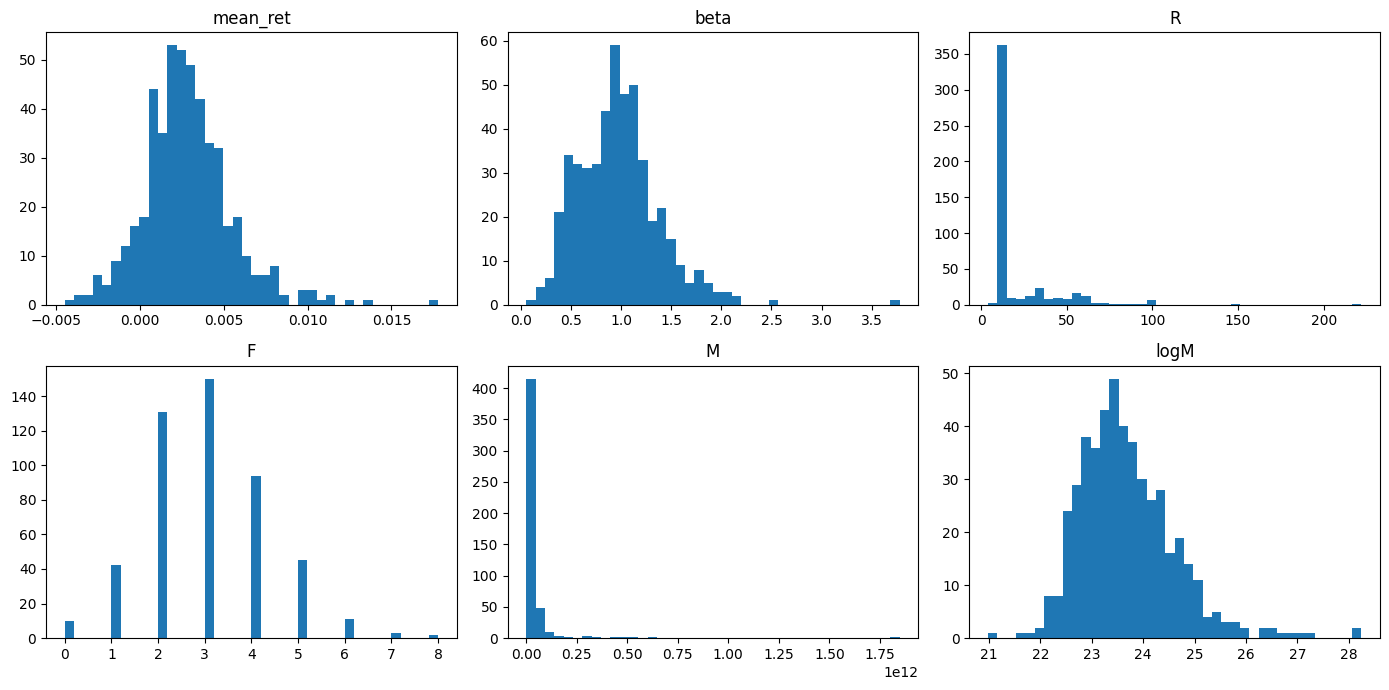

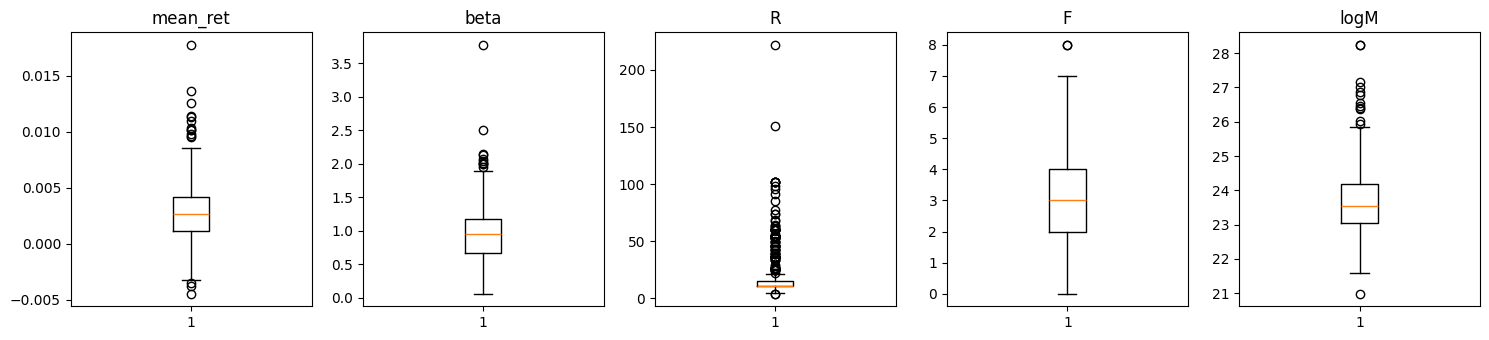

Standardised check (mean ~0, std ~1): [-0. -0.] [1. 1.] [-0. -0. -0.] [1. 1. 1.]


In [12]:
RR_COLS, RFM_COLS = ["mean_ret", "beta"], ["R", "F", "logM"]
print("Skewness:\n", features[["mean_ret", "beta", "R", "F", "M", "logM"]].skew().round(2))
q1, q3 = features[["mean_ret", "beta", "R", "F", "logM"]].quantile(.25), features[["mean_ret", "beta", "R", "F", "logM"]].quantile(.75)
iqr = q3 - q1
outl = ((features[q1.index] < q1 - 1.5 * iqr) | (features[q1.index] > q3 + 1.5 * iqr)).sum()
print("IQR outlier counts:\n", outl)

fig, ax = plt.subplots(2, 3, figsize=(14, 7))
for a, c in zip(ax.ravel(), ["mean_ret", "beta", "R", "F", "M", "logM"]):
    a.hist(features[c], bins=40); a.set_title(c)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/feature_distributions.png", dpi=150); plt.show()

fig, ax = plt.subplots(1, 5, figsize=(15, 3.5))
for a, c in zip(ax, ["mean_ret", "beta", "R", "F", "logM"]):
    a.boxplot(features[c], vert=True); a.set_title(c)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/feature_boxplots.png", dpi=150); plt.show()

# log1p on M only (required). R and F are left on their raw scale: documented decision, outliers are NOT removed
# (extreme but genuine); Ward/K-means are distance based, so outliers can pull centroids -> a log1p(R) sensitivity check is run in 2.5.
X_rr = StandardScaler().fit_transform(features[RR_COLS])
X_rfm = StandardScaler().fit_transform(features[RFM_COLS])
print("Standardised check (mean ~0, std ~1):", np.round(X_rr.mean(0), 6), np.round(X_rr.std(0), 3),
      np.round(X_rfm.mean(0), 6), np.round(X_rfm.std(0), 3))
N = len(features)

features_view = features.copy()
features_view["M_usd_bn"] = features_view["M"] / 1e9
prof_cols = ["mean_ret", "beta", "R", "F", "M_usd_bn"]

def relabel(lab, ref):
    """Cluster ids are arbitrary; renumber 0..k-1 by ascending mean of a reference feature for readability."""
    order = pd.Series(ref).groupby(lab).mean().sort_values().index
    return pd.Series(lab).map({o: i for i, o in enumerate(order)}).values

def fit_labels(algo, X, k):
    if algo == "ward":
        return AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X)   # Ward => Euclidean
    return KMeans(n_clusters=k, n_init=50, random_state=SEED).fit_predict(X)

2.2 / 2.3 Cluster count diagnostics (k=2:8)


 ('ward', 'RR')
 k  silhouette  min_size                    sizes
 2       0.340        92                   396/92
 3       0.293        92               212/184/92
 4       0.265        92            184/114/98/92
 5       0.287        48         136/114/98/92/48
 6       0.304         5       136/114/98/87/48/5
 7       0.306         5    114/114/98/87/48/22/5
 8       0.314         5 114/114/98/56/48/31/22/5

 ('ward', 'RFM')
 k  silhouette  min_size                  sizes
 2       0.369        86                 402/86
 3       0.261        86             223/179/86
 4       0.251        86          179/137/86/86
 5       0.270        10       179/137/86/76/10
 6       0.291        10    161/137/86/76/18/10
 7       0.280        10  137/90/86/76/71/18/10
 8       0.282         1 137/90/86/76/71/18/9/1

 ('kmeans', 'RR')
 k  silhouette  inertia  min_size                   sizes
 2       0.387  625.010       143                 345/143
 3       0.328  464.077       119             

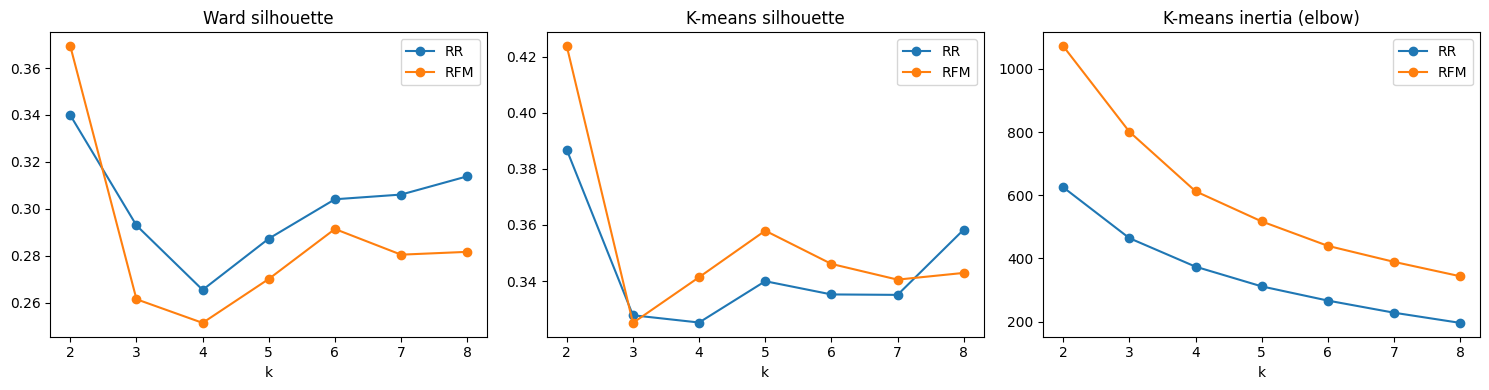

In [13]:
KS = range(2, 9)
def sizes(lab):
    return "/".join(map(str, sorted(np.bincount(lab), reverse=True)))

def eval_ward(X):
    rows = []
    for k in KS:
        lab = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X)
        rows.append({"k": k, "silhouette": silhouette_score(X, lab), "min_size": np.bincount(lab).min(), "sizes": sizes(lab)})
    return pd.DataFrame(rows)

def eval_km(X):
    rows = []
    for k in KS:
        km = KMeans(n_clusters=k, n_init=50, random_state=SEED).fit(X)               # 50 initialisations, fixed seed
        rows.append({"k": k, "silhouette": silhouette_score(X, km.labels_), "inertia": km.inertia_,
                     "min_size": np.bincount(km.labels_).min(), "sizes": sizes(km.labels_)})
    return pd.DataFrame(rows)

diag = {("ward", "RR"): eval_ward(X_rr), ("ward", "RFM"): eval_ward(X_rfm),
        ("kmeans", "RR"): eval_km(X_rr), ("kmeans", "RFM"): eval_km(X_rfm)}
for key, d in diag.items():
    print("\n", key); print(d.round(3).to_string(index=False))
    d.to_csv(f"{OUT_DIR}/diagnostics_{key[0]}_{key[1]}.csv", index=False)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for key, d in diag.items():
    ax[0 if key[0] == "ward" else 1].plot(d["k"], d["silhouette"], marker="o", label=key[1])
    if key[0] == "kmeans":
        ax[2].plot(d["k"], d["inertia"], marker="o", label=key[1])
ax[0].set_title("Ward silhouette"); ax[1].set_title("K-means silhouette"); ax[2].set_title("K-means inertia (elbow)")
for a in ax: a.set_xlabel("k"); a.legend()
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/k_diagnostics.png", dpi=150); plt.show()

In [14]:
# Interpretable profiles for k = 2..5 (original units, medians) so the cluster count is justified by profiles as well
# as silhouette and sizes. Read this output BEFORE deciding CHOSEN_K / K_OVERRIDE in the next cell.
rows = []
for name, X, ref in (("RR", X_rr, "beta"), ("RFM", X_rfm, "M")):
    for algo in ("ward", "kmeans"):
        for k in (2, 3, 4, 5):
            lab = relabel(fit_labels(algo, X, k), features[ref].values)
            g = features_view.groupby(lab)[prof_cols]
            p = pd.concat([g.size().rename("n"), g.median().add_suffix("_med")], axis=1)
            p.insert(0, "cluster", p.index); p.insert(0, "k", k); p.insert(0, "algo", algo); p.insert(0, "matrix", name)
            rows.append(p)
            print(f"\n{algo} {name} k={k} | silhouette {silhouette_score(X, lab):.3f}")
            print(p.drop(columns=["matrix", "algo", "k"]).round(4).to_string(index=False))
pd.concat(rows).to_csv(f"{OUT_DIR}/profiles_k2_to_k5.csv", index=False)

# Ward solutions are nested: check the k=2 -> k=3 split
for name, X, ref in (("RR", X_rr, "beta"), ("RFM", X_rfm, "M")):
    l2 = relabel(fit_labels("ward", X, 2), features[ref].values); l3 = relabel(fit_labels("ward", X, 3), features[ref].values)
    print(f"\nWard {name}: k=2 (rows) vs k=3 (cols)"); print(pd.crosstab(pd.Series(l2, name="k2"), pd.Series(l3, name="k3")))


ward RR k=2 | silhouette 0.340
 cluster   n  mean_ret_med  beta_med  R_med  F_med  M_usd_bn_med
       0 396        0.0021    0.8850   11.0    3.0       15.3252
       1  92        0.0055    1.2177   11.0    3.0       24.1841

ward RR k=3 | silhouette 0.293
 cluster   n  mean_ret_med  beta_med  R_med  F_med  M_usd_bn_med
       0 212        0.0025    0.6319   11.0    3.0       16.0473
       1 184        0.0018    1.0886   11.0    3.0       14.7247
       2  92        0.0055    1.2177   11.0    3.0       24.1841

ward RR k=4 | silhouette 0.265
 cluster   n  mean_ret_med  beta_med  R_med  F_med  M_usd_bn_med
       0 114        0.0012    0.5703   11.0    3.0       14.3861
       1  98        0.0039    0.6663   11.0    3.0       17.6494
       2 184        0.0018    1.0886   11.0    3.0       14.7247
       3  92        0.0055    1.2177   11.0    3.0       24.1841

ward RR k=5 | silhouette 0.287
 cluster   n  mean_ret_med  beta_med  R_med  F_med  M_usd_bn_med
       0 114        0.0012 

In [15]:
# Choose k: highest silhouette among solutions whose smallest cluster has >= 5% of shares.
# To override after reading the profiles above, fill K_OVERRIDE, e.g. {("ward", "RR"): 3}, then re-run from here.
def pick_k(d, min_frac=0.05):
    ok = d[d["min_size"] >= min_frac * N]
    d = ok if len(ok) else d
    return int(d.loc[d["silhouette"].idxmax(), "k"])
K_OVERRIDE = {}
CHOSEN_K = {key: pick_k(d) for key, d in diag.items()}
CHOSEN_K.update(K_OVERRIDE)
print("Selected k:", CHOSEN_K)

Selected k: {('ward', 'RR'): 2, ('ward', 'RFM'): 2, ('kmeans', 'RR'): 2, ('kmeans', 'RFM'): 2}


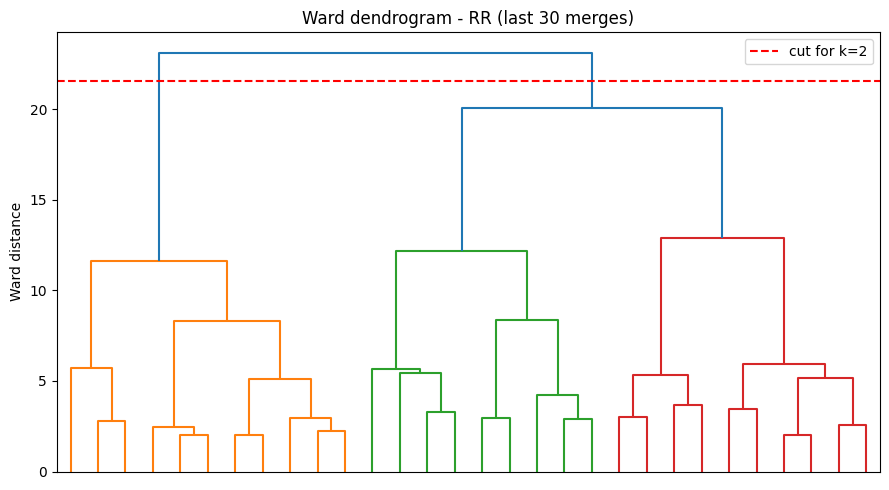

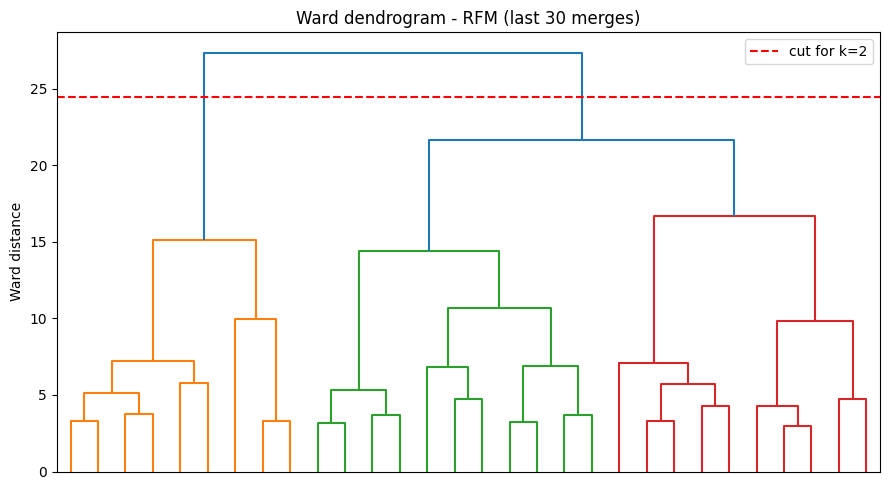

Cophenetic correlation (how faithfully the tree preserves pairwise distances): {'RR': np.float64(0.463), 'RFM': np.float64(0.481)}


In [16]:
# One dendrogram per feature matrix (Ward, Euclidean) with the cut implied by the chosen k
coph = {}
for name, X in (("RR", X_rr), ("RFM", X_rfm)):
    Z = linkage(X, method="ward", metric="euclidean")
    coph[name] = cophenet(Z, pdist(X))[0]
    k = CHOSEN_K[("ward", name)]
    fig, a = plt.subplots(figsize=(9, 5))
    dendrogram(Z, truncate_mode="lastp", p=30, ax=a, no_labels=True)
    a.axhline((Z[-(k - 1), 2] + Z[-k, 2]) / 2, color="r", ls="--", label=f"cut for k={k}")
    a.set_title(f"Ward dendrogram - {name} (last 30 merges)"); a.set_ylabel("Ward distance"); a.legend()
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/dendrogram_{name}.png", dpi=150); plt.show()
print("Cophenetic correlation (how faithfully the tree preserves pairwise distances):", {k: round(v, 3) for k, v in coph.items()})

In [17]:
# K-means initialisation stability at the chosen k (multiple initialisations + several seeds)
stab = []
for name, X in (("RR", X_rr), ("RFM", X_rfm)):
    k = CHOSEN_K[("kmeans", name)]
    base = KMeans(n_clusters=k, n_init=50, random_state=SEED).fit(X)
    multi = [KMeans(n_clusters=k, n_init=50, random_state=s).fit(X) for s in range(10)]
    single = [KMeans(n_clusters=k, n_init=1, random_state=s).fit(X) for s in range(30)]
    best = min(m.inertia_ for m in multi)
    stab.append({"matrix": name, "k": k, "inertia_seed42_n50": base.inertia_,
                 "inertia_range_10_seeds_n50": f"{min(m.inertia_ for m in multi):.3f} - {max(m.inertia_ for m in multi):.3f}",
                 "min_ARI_vs_seed42 (10 seeds, n_init=50)": round(min(adjusted_rand_score(base.labels_, m.labels_) for m in multi), 3),
                 "single_init_inertia_range": f"{min(m.inertia_ for m in single):.3f} - {max(m.inertia_ for m in single):.3f}",
                 "share_of_single_inits_reaching_best": round(float(np.mean([np.isclose(m.inertia_, best, rtol=1e-6) for m in single])), 2)})
stab = pd.DataFrame(stab)
print(stab.T.to_string())
stab.to_csv(f"{OUT_DIR}/kmeans_initialisation_stability.csv", index=False)

                                                         0                    1
matrix                                                  RR                  RFM
k                                                        2                    2
inertia_seed42_n50                                625.0104          1071.585297
inertia_range_10_seeds_n50               625.010 - 625.010  1071.585 - 1071.585
min_ARI_vs_seed42 (10 seeds, n_init=50)                1.0                  1.0
single_init_inertia_range                625.010 - 625.041  1071.585 - 1174.571
share_of_single_inits_reaching_best                   0.93                 0.27


2.4 Profiles + four baseline solutions

In [18]:
labels = {}
for (algo, name), k in CHOSEN_K.items():
    X = X_rr if name == "RR" else X_rfm
    ref = features["beta"].values if name == "RR" else features["M"].values
    labels[(algo, name)] = relabel(fit_labels(algo, X, k), ref)

assign = features[["sector"]].copy()
for (algo, name), lab in labels.items():
    assign[f"{algo}_{name}"] = lab
assign.to_csv(f"{OUT_DIR}/cluster_assignments.csv")

profiles = {}
for key, lab in labels.items():
    g = features_view.groupby(lab)[prof_cols]
    p = pd.concat([g.size().rename("n"), g.mean().add_suffix("_mean"), g.median().add_suffix("_median")], axis=1)
    profiles[key] = p
    p.to_csv(f"{OUT_DIR}/profile_{key[0]}_{key[1]}.csv")
    print("\nProfile (original units):", key); print(p.round(4).to_string())

# descriptive cluster names from standardised cluster means (|z| > 0.5), used in plots
DISPLAY = {"mean_ret": "return", "beta": "beta", "R": "R", "F": "F", "logM": "M"}
def cluster_names(lab, cols):
    z = (features[cols] - features[cols].mean()) / features[cols].std()
    names = {}
    for c in np.unique(lab):
        zc = z[lab == c].mean()
        parts = [f"{'high' if v > 0 else 'low'} {DISPLAY[col]}" for col, v in zc.items() if abs(v) > 0.5]
        names[c] = f"C{c}: " + (", ".join(parts) if parts else "near average")
    return names
names = {key: cluster_names(lab, RR_COLS if key[1] == "RR" else RFM_COLS) for key, lab in labels.items()}
for key, nm in names.items():
    print(key, nm)


Profile (original units): ('ward', 'RR')
     n  mean_ret_mean  beta_mean   R_mean  F_mean  M_usd_bn_mean  mean_ret_median  beta_median  R_median  F_median  M_usd_bn_median
0  396         0.0021     0.8985  19.6263  2.9394        30.1312           0.0021       0.8850      11.0       3.0          15.3252
1   92         0.0063     1.2981  23.6739  3.1957        78.7809           0.0055       1.2177      11.0       3.0          24.1841

Profile (original units): ('ward', 'RFM')
     n  mean_ret_mean  beta_mean   R_mean  F_mean  M_usd_bn_mean  mean_ret_median  beta_median  R_median  F_median  M_usd_bn_median
0  402         0.0028     0.9603  12.5572  3.2040        37.3893           0.0027       0.9341      11.0       3.0          15.3958
1   86         0.0031     1.0371  57.0000  1.9767        48.2481           0.0026       1.0514      54.0       2.0          21.4501

Profile (original units): ('kmeans', 'RR')
     n  mean_ret_mean  beta_mean   R_mean  F_mean  M_usd_bn_mean  mean_ret_medi

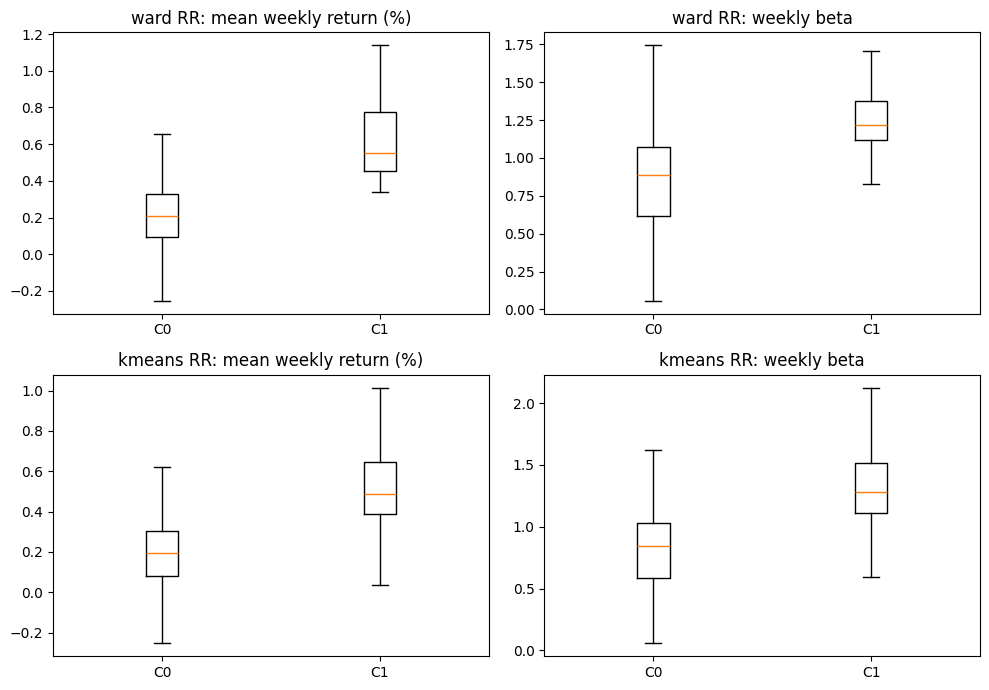

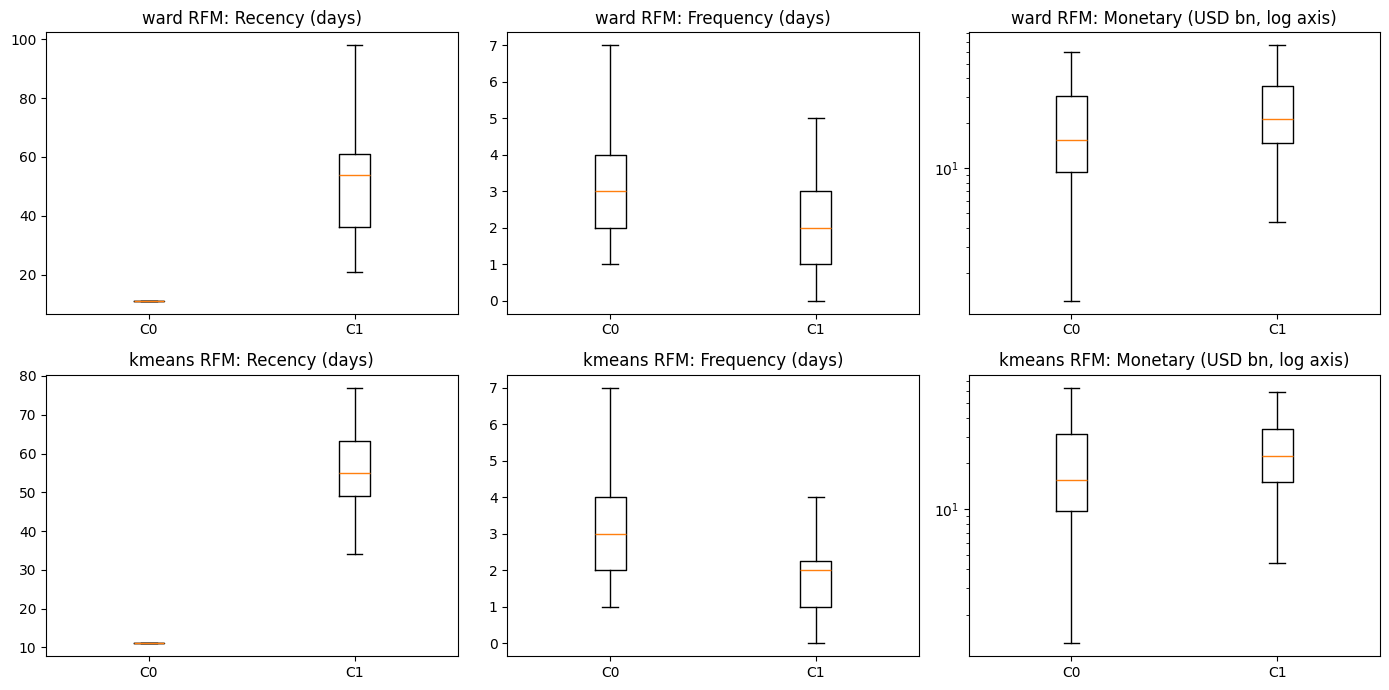

In [19]:
# Original-unit profile plots (boxplots per cluster)
def box_by_cluster(ax, series, lab, title, log=False):
    cl = np.unique(lab)
    ax.boxplot([series[lab == c].values for c in cl], showfliers=False)
    ax.set_xticklabels([f"C{c}" for c in cl]); ax.set_title(title)
    if log: ax.set_yscale("log")

fig, ax = plt.subplots(2, 2, figsize=(10, 7))
for i, algo in enumerate(("ward", "kmeans")):
    lab = labels[(algo, "RR")]
    box_by_cluster(ax[i, 0], features["mean_ret"] * 100, lab, f"{algo} RR: mean weekly return (%)")
    box_by_cluster(ax[i, 1], features["beta"], lab, f"{algo} RR: weekly beta")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/profiles_RR_boxplots.png", dpi=150); plt.show()

fig, ax = plt.subplots(2, 3, figsize=(14, 7))
for i, algo in enumerate(("ward", "kmeans")):
    lab = labels[(algo, "RFM")]
    box_by_cluster(ax[i, 0], features["R"], lab, f"{algo} RFM: Recency (days)")
    box_by_cluster(ax[i, 1], features["F"], lab, f"{algo} RFM: Frequency (days)")
    box_by_cluster(ax[i, 2], features_view["M_usd_bn"], lab, f"{algo} RFM: Monetary (USD bn, log axis)", log=True)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/profiles_RFM_boxplots.png", dpi=150); plt.show()

PCA explained variance (RFM): [0.458 0.336] | loadings:
        PC1   PC2
R     0.71  0.02
F    -0.65  0.40
logM  0.27  0.91


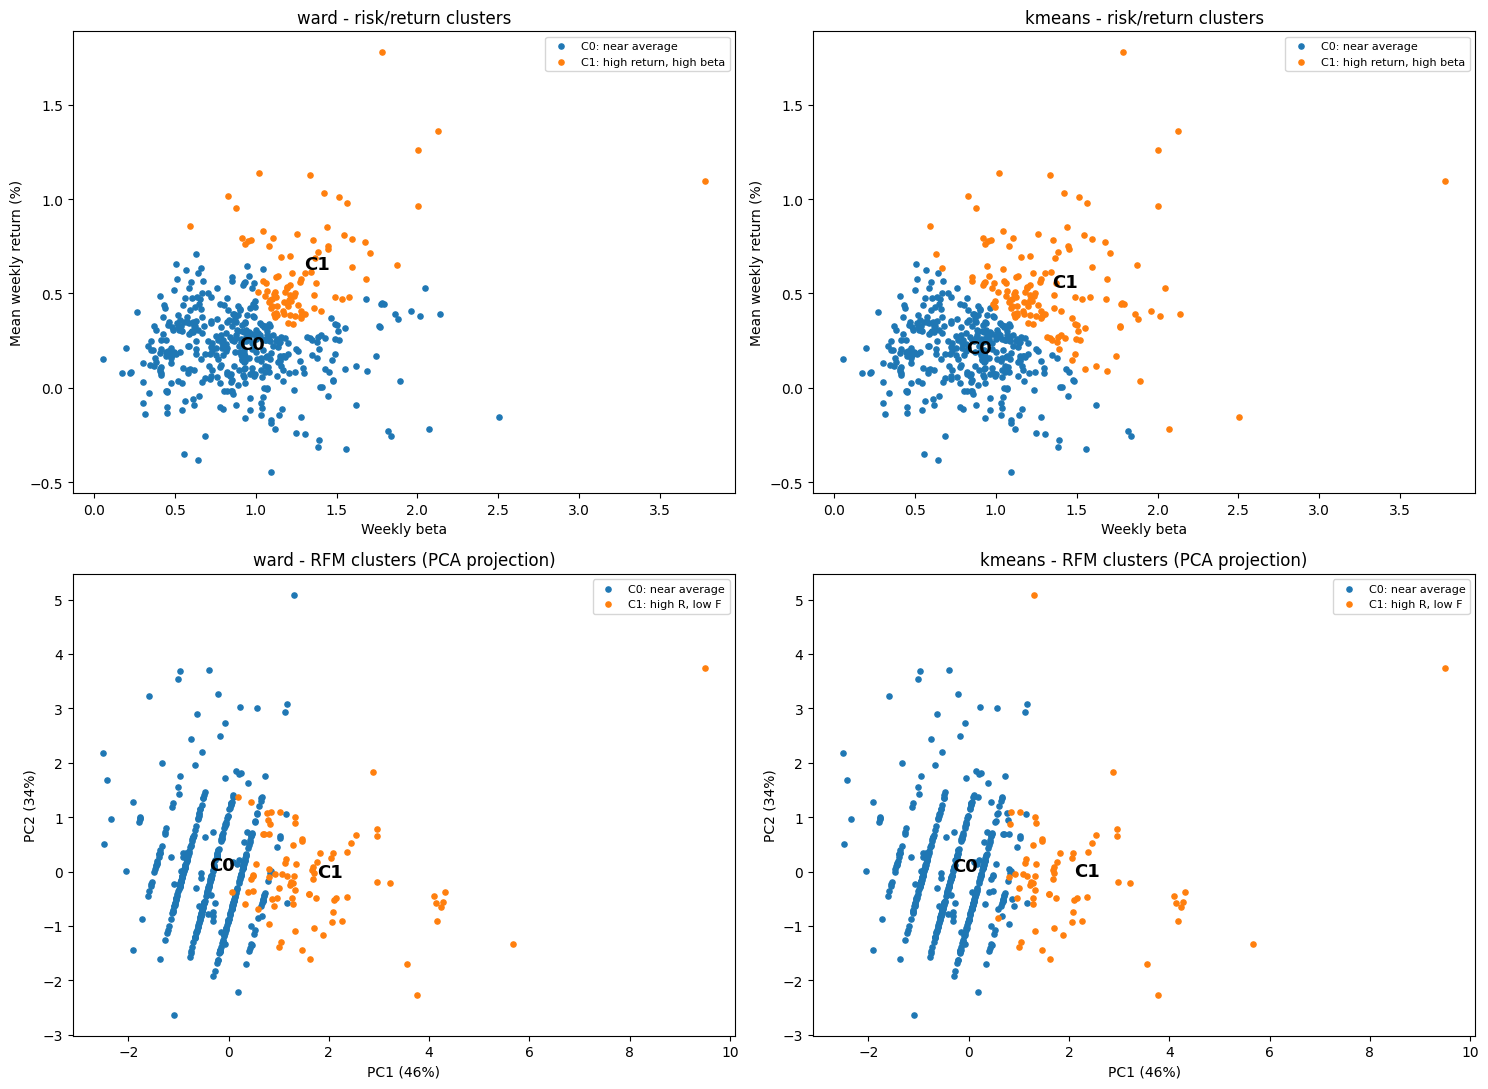

In [20]:
# Risk-return uses the two raw features (no reduction). RFM uses PCA on the standardised features (2-D projection only:
# distances in the plot are approximate; clustering used all three standardised features).
pca = PCA(n_components=2, random_state=SEED).fit(X_rfm)
P = pca.transform(X_rfm)
print("PCA explained variance (RFM):", pca.explained_variance_ratio_.round(3), "| loadings:\n",
      pd.DataFrame(pca.components_.T, index=RFM_COLS, columns=["PC1", "PC2"]).round(2))

fig, ax = plt.subplots(2, 2, figsize=(15, 11))
for i, algo in enumerate(("ward", "kmeans")):
    lab = labels[(algo, "RR")]
    a = ax[0, i]
    for c in np.unique(lab):
        m = lab == c
        a.scatter(features["beta"][m], features["mean_ret"][m] * 100, s=14, label=names[(algo, "RR")][c])
        a.annotate(f"C{c}", (features["beta"][m].mean(), features["mean_ret"][m].mean() * 100), fontsize=13, weight="bold")
    a.set_xlabel("Weekly beta"); a.set_ylabel("Mean weekly return (%)"); a.set_title(f"{algo} - risk/return clusters"); a.legend(fontsize=8)
    lab = labels[(algo, "RFM")]
    a = ax[1, i]
    for c in np.unique(lab):
        m = lab == c
        a.scatter(P[m, 0], P[m, 1], s=14, label=names[(algo, "RFM")][c])
        a.annotate(f"C{c}", (P[m, 0].mean(), P[m, 1].mean()), fontsize=13, weight="bold")
    a.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%})"); a.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%})")
    a.set_title(f"{algo} - RFM clusters (PCA projection)"); a.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/cluster_maps.png", dpi=150); plt.show()

In [21]:
# Algorithm comparison on the SAME shares (cluster numbers are arbitrary, so use ARI and crosstabs)
for name in ("RR", "RFM"):
    w, k_ = labels[("ward", name)], labels[("kmeans", name)]
    X = X_rr if name == "RR" else X_rfm
    print(f"\n{name}: ARI(Ward, K-means) = {adjusted_rand_score(w, k_):.3f}")
    print(pd.crosstab(pd.Series(w, name="Ward"), pd.Series(k_, name="KMeans")))
    for algo in ("ward", "kmeans"):
        print(f"  silhouette {algo}: {silhouette_score(X, labels[(algo, name)]):.3f}")
print("\nARI risk/return vs RFM (Ward):", round(adjusted_rand_score(labels[("ward", "RR")], labels[("ward", "RFM")]), 3))
print("ARI risk/return vs RFM (K-means):", round(adjusted_rand_score(labels[("kmeans", "RR")], labels[("kmeans", "RFM")]), 3))


RR: ARI(Ward, K-means) = 0.599
KMeans    0   1
Ward           
0       345  51
1         0  92
  silhouette ward: 0.340
  silhouette kmeans: 0.387

RFM: ARI(Ward, K-means) = 0.780
KMeans    0   1
Ward           
0       400   2
1        20  66
  silhouette ward: 0.369
  silhouette kmeans: 0.424

ARI risk/return vs RFM (Ward): 0.03
ARI risk/return vs RFM (K-means): 0.005


2.5 RFM sensitivity and correlated inputs

Pearson:
           R      F   logM
R     1.000 -0.346  0.153
F    -0.346  1.000  0.013
logM  0.153  0.013  1.000 

Spearman:
           R      F   logM
R     1.000 -0.198  0.138
F    -0.198  1.000 -0.048
logM  0.138 -0.048  1.000


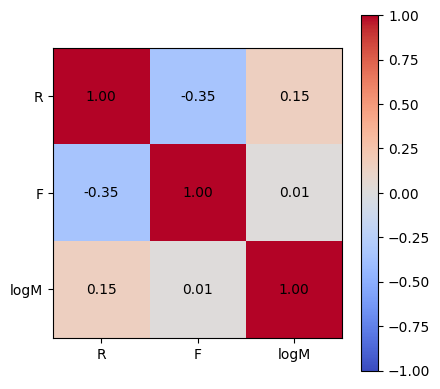


Eigenvalue share of the RFM correlation matrix (overlap of information): [0.458 0.336 0.206]

Which feature drives the full-RFM Ward split?
      eta2_by_full_RFM_clusters  share_of_between_cluster_SS
R                         0.633                        0.828
F                         0.124                        0.162
logM                      0.008                        0.010


In [22]:
# 2.5.1 Correlations among R, F, log1p(M)
corr_p = features[RFM_COLS].corr()
corr_s = features[RFM_COLS].corr(method="spearman")
print("Pearson:\n", corr_p.round(3), "\n\nSpearman:\n", corr_s.round(3))
corr_p.to_csv(f"{OUT_DIR}/rfm_correlation.csv")
fig, a = plt.subplots(figsize=(4.5, 4))
im = a.imshow(corr_p, vmin=-1, vmax=1, cmap="coolwarm"); a.set_xticks(range(3)); a.set_yticks(range(3))
a.set_xticklabels(RFM_COLS); a.set_yticklabels(RFM_COLS)
for i in range(3):
    for j in range(3):
        a.text(j, i, f"{corr_p.iloc[i, j]:.2f}", ha="center", va="center")
plt.colorbar(im); plt.tight_layout(); plt.savefig(f"{OUT_DIR}/rfm_corr.png", dpi=150); plt.show()
# Why it matters: standardising gives each feature unit variance, but if two features are strongly correlated they carry
# overlapping information, so that shared dimension counts more than once in Euclidean distance. This is potential extra
# influence, NOT proof of dominance -> link to clustering distances with the evidence below.

lab_full = labels[("ward", "RFM")]
def eta_sq(values, lab):
    """Share of variance in `values` explained by cluster membership."""
    v = pd.Series(np.asarray(values)).reset_index(drop=True); l = pd.Series(np.asarray(lab))
    return float(sum(len(g) * (g.mean() - v.mean()) ** 2 for _, g in v.groupby(l)) / ((v - v.mean()) ** 2).sum())

def bss_share(X, lab):
    """Share of total between-cluster sum of squares contributed by each standardised feature (distance contribution)."""
    cl = np.unique(lab)
    bss = np.array([sum((lab == c).sum() * X[lab == c, j].mean() ** 2 for c in cl) for j in range(X.shape[1])])
    return bss / bss.sum()

ev = np.linalg.eigvalsh(corr_p.values)[::-1]
print("\nEigenvalue share of the RFM correlation matrix (overlap of information):", np.round(ev / ev.sum(), 3))
link = pd.DataFrame({"eta2_by_full_RFM_clusters": [eta_sq(features[c].values, lab_full) for c in RFM_COLS],
                     "share_of_between_cluster_SS": bss_share(X_rfm, lab_full)}, index=RFM_COLS)
print("\nWhich feature drives the full-RFM Ward split?"); print(link.round(3))
link.to_csv(f"{OUT_DIR}/rfm_feature_influence.csv")

In [23]:
# 2.5.2 Remove Monetary: same shares, same Ward method, same k, fresh scaling
k_sel = CHOSEN_K[("ward", "RFM")]
X_rf = StandardScaler().fit_transform(features[["R", "F"]])
lab_rf_raw = AgglomerativeClustering(n_clusters=k_sel, linkage="ward").fit_predict(X_rf)
lab_full = labels[("ward", "RFM")]
ari = adjusted_rand_score(lab_full, lab_rf_raw)                 # unaffected by arbitrary numbering

# align R,F-only cluster ids to the full-RFM ids (Hungarian matching on overlap) so profiles compare like with like
ct = pd.crosstab(lab_full, lab_rf_raw).values
rr_, cc_ = linear_sum_assignment(-ct)
mapping = {c_i: r_i for r_i, c_i in zip(rr_, cc_)}
lab_rf = np.array([mapping[x] for x in lab_rf_raw])
print(f"k={k_sel} | ARI(full RFM vs R,F only) = {ari:.3f} | silhouette R,F only = {silhouette_score(X_rf, lab_rf):.3f} "
      f"(not comparable with the 3-feature silhouette: different feature space)")
print(pd.crosstab(pd.Series(lab_full, name="Full RFM"), pd.Series(lab_rf, name="R,F only (aligned)")))

def tv_profile(lab, prefix):
    g = features_view.groupby(lab)
    return pd.DataFrame({f"{prefix}_n": g.size(), f"{prefix}_median_M_usd_bn": g["M_usd_bn"].median(),
                         f"{prefix}_mean_M_usd_bn": g["M_usd_bn"].mean(),
                         f"{prefix}_median_R": g["R"].median(), f"{prefix}_median_F": g["F"].median()})
tv = pd.concat([tv_profile(lab_full, "full_RFM"), tv_profile(lab_rf, "RF_only")], axis=1)
print(tv.round(3).T.to_string())
print("eta^2 of log1p(M) explained by clusters: full RFM =", round(eta_sq(features["logM"].values, lab_full), 3),
      "| R,F only =", round(eta_sq(features["logM"].values, lab_rf), 3))
print("Traded value is only a liquidity proxy (no spread / price impact measured).")
assign["ward_RF_only"] = lab_rf
assign.to_csv(f"{OUT_DIR}/cluster_assignments.csv")
tv.to_csv(f"{OUT_DIR}/monetary_removal_traded_value_profiles.csv")

k=2 | ARI(full RFM vs R,F only) = 0.923 | silhouette R,F only = 0.521 (not comparable with the 3-feature silhouette: different feature space)
R,F only (aligned)    0   1
Full RFM                   
0                   396   6
1                     2  84
                                0       1
full_RFM_n                402.000  86.000
full_RFM_median_M_usd_bn   15.396  21.450
full_RFM_mean_M_usd_bn     37.389  48.248
full_RFM_median_R          11.000  54.000
full_RFM_median_F           3.000   2.000
RF_only_n                 398.000  90.000
RF_only_median_M_usd_bn    15.460  20.490
RF_only_mean_M_usd_bn      37.740  46.215
RF_only_median_R           11.000  53.500
RF_only_median_F            3.000   2.000
eta^2 of log1p(M) explained by clusters: full RFM = 0.008 | R,F only = 0.004
Traded value is only a liquidity proxy (no spread / price impact measured).


In [24]:
# Sensitivity of the Ward RFM solution to the untransformed, heavily skewed R (log1p(R) instead of R)
X_logR = StandardScaler().fit_transform(np.column_stack([np.log1p(features["R"]), features["F"], features["logM"]]))
lab_logR = AgglomerativeClustering(n_clusters=CHOSEN_K[("ward", "RFM")], linkage="ward").fit_predict(X_logR)
print("ARI(Ward RFM with R, Ward RFM with log1p(R)) =", round(adjusted_rand_score(labels[("ward", "RFM")], lab_logR), 3))
print("Skew of R:", round(float(features["R"].skew()), 2), "-> log1p(R):", round(float(np.log1p(features["R"]).skew()), 2))

ARI(Ward RFM with R, Ward RFM with log1p(R)) = 0.905
Skew of R: 3.65 -> log1p(R): 1.58


# **Task 03 - Business intelligence review**

3.2.1 Sector composition

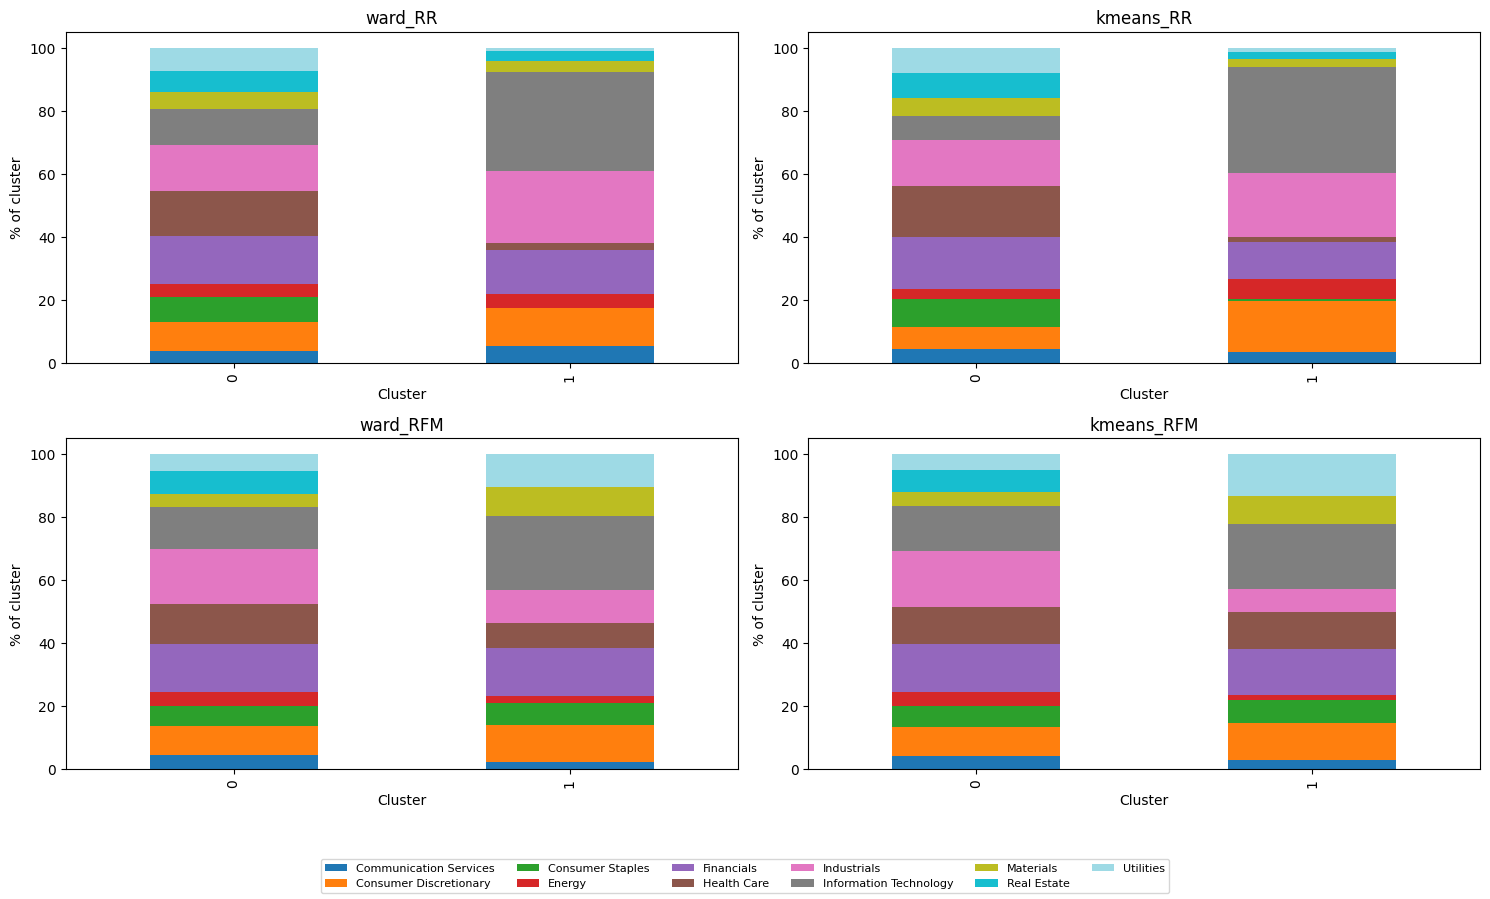

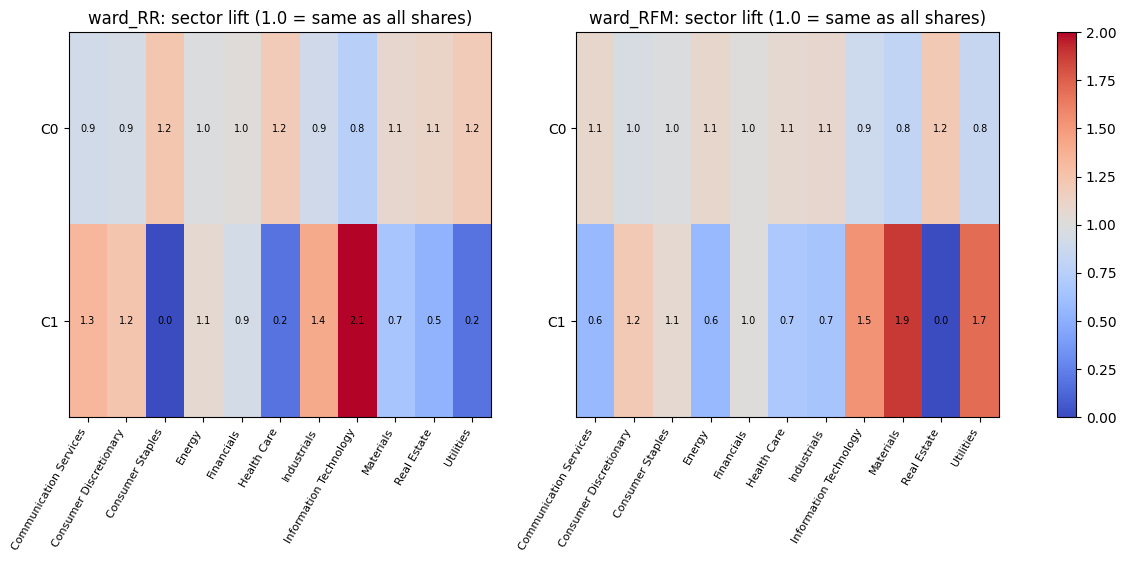

sector   Communication Services  Consumer Discretionary  Consumer Staples  Energy  Financials  Health Care  Industrials  Information Technology  Materials  Real Estate  Utilities
ward_RR                                                                                                                                                                           
0                            15                      36                32      16          61           56           58                      45         21           27         29
1                             5                      11                 0       4          13            2           21                      29          3            3          1


In [25]:
sol_cols = ["ward_RR", "kmeans_RR", "ward_RFM", "kmeans_RFM"]
fig, ax = plt.subplots(2, 2, figsize=(15, 9))
for a, key in zip(ax.ravel(), sol_cols):
    ct = pd.crosstab(assign[key], assign["sector"], normalize="index") * 100
    ct.plot(kind="bar", stacked=True, ax=a, legend=False, colormap="tab20")
    a.set_title(key); a.set_ylabel("% of cluster"); a.set_xlabel("Cluster")
    pd.crosstab(assign[key], assign["sector"]).to_csv(f"{OUT_DIR}/sector_counts_{key}.csv")
handles, labs = ax[0, 0].get_legend_handles_labels()
fig.legend(handles, labs, loc="lower center", ncol=6, fontsize=8)
plt.tight_layout(rect=[0, 0.08, 1, 1])
plt.savefig(f"{OUT_DIR}/sector_composition.png", dpi=150); plt.show()

# Over/under-representation: share of the cluster in a sector divided by the sector's share of all clustered shares
universe = assign["sector"].value_counts(normalize=True)
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
for a, key in zip(ax, ("ward_RR", "ward_RFM")):
    lift = (pd.crosstab(assign[key], assign["sector"], normalize="index") / universe).round(2)
    lift.to_csv(f"{OUT_DIR}/sector_lift_{key}.csv")
    im = a.imshow(lift.values, cmap="coolwarm", vmin=0, vmax=2, aspect="auto")
    a.set_xticks(range(lift.shape[1])); a.set_xticklabels(lift.columns, rotation=60, ha="right", fontsize=8)
    a.set_yticks(range(lift.shape[0])); a.set_yticklabels([f"C{c}" for c in lift.index])
    for i in range(lift.shape[0]):
        for j in range(lift.shape[1]):
            a.text(j, i, f"{lift.values[i, j]:.1f}", ha="center", va="center", fontsize=7)
    a.set_title(f"{key}: sector lift (1.0 = same as all shares)")
plt.colorbar(im, ax=ax); plt.savefig(f"{OUT_DIR}/sector_lift.png", dpi=150, bbox_inches="tight"); plt.show()
print(pd.crosstab(assign["ward_RR"], assign["sector"]).to_string())

3.2.3 Return dependencies

In [26]:
# Average pairwise correlation of weekly returns within groups, and between groups
C = w_ret[features.index].corr()
n_all = len(C)
def within_sum(idx):
    sub = C.loc[idx, idx].values
    return sub.sum() - len(idx), len(idx) * (len(idx) - 1)          # sum of off-diagonal correlations, number of pairs
rows = [{"grouping": "all shares", "group": "-", "n": n_all, "mean_pairwise_corr": (C.values.sum() - n_all) / (n_all * (n_all - 1))}]
for key in sol_cols + ["sector"]:
    tot_s, tot_p = 0.0, 0
    for g in sorted(assign[key].unique()):
        idx = assign.index[assign[key] == g]
        if len(idx) < 2: continue
        s, p = within_sum(idx); tot_s += s; tot_p += p
        rows.append({"grouping": key, "group": g, "n": len(idx), "mean_pairwise_corr": s / p})
    cross = ((C.values.sum() - n_all) - tot_s) / (n_all * (n_all - 1) - tot_p)
    rows.append({"grouping": key, "group": "between groups (average)", "n": n_all, "mean_pairwise_corr": cross})
dep = pd.DataFrame(rows)
print(dep.round(3).to_string(index=False))
dep.to_csv(f"{OUT_DIR}/return_dependency_by_cluster.csv", index=False)

  grouping                    group   n  mean_pairwise_corr
all shares                        - 488               0.299
   ward_RR                        0 396               0.297
   ward_RR                        1  92               0.374
   ward_RR between groups (average) 488               0.297
 kmeans_RR                        0 345               0.302
 kmeans_RR                        1 143               0.372
 kmeans_RR between groups (average) 488               0.281
  ward_RFM                        0 402               0.304
  ward_RFM                        1  86               0.277
  ward_RFM between groups (average) 488               0.290
kmeans_RFM                        0 420               0.304
kmeans_RFM                        1  68               0.271
kmeans_RFM between groups (average) 488               0.286
    sector   Communication Services  20               0.275
    sector   Consumer Discretionary  47               0.363
    sector         Consumer Staples  32 

Reproducibility record

In [27]:
with open(f"{OUT_DIR}/run_metadata.txt", "w") as f:
    f.write(f"ticker_list_retrieval_date={retrieval_date}\nprice_snapshot_date={snapshot_date}\ndata_source={data_source}\n"
            f"price_library=yfinance {yf.__version__} (auto_adjust=False)\nstudy={START}..{END} (end exclusive)\n"
            f"observation_date={obs_date.date()}\nweekly_obs={n_weeks}\nseed={SEED}\nchosen_k={CHOSEN_K}\n"
            f"k_override={K_OVERRIDE}\nincluded_tickers={len(valid)}\nexcluded_tickers={len(excl_df)}\n"
            f"clustered_tickers={len(features)}\ncorporate_action_flags={len(flag_df)}\n"
            f"python={sys.version.split()[0]}\n")
print(open(f"{OUT_DIR}/run_metadata.txt").read())

try:
    out = subprocess.run([sys.executable, "-m", "pip", "freeze"], capture_output=True, text=True).stdout.splitlines()
    keep = [l for l in out if any(l.lower().startswith(p) for p in ("pandas", "numpy", "yfinance", "scikit-learn", "scipy", "matplotlib", "lxml", "requests"))]
    open("requirements.txt", "w").write("\n".join(keep) + "\n")
    open(f"{OUT_DIR}/requirements.txt", "w").write("\n".join(keep) + "\n")
    print("requirements.txt written:", keep)
except Exception as e:
    print("Could not write requirements.txt:", e)

ticker_list_retrieval_date=2026-11-24
price_snapshot_date=2026-11-24
data_source=yfinance live download
price_library=yfinance 0.2.66 (auto_adjust=False)
study=2021-01-01..2025-01-01 (end exclusive)
observation_date=2024-12-31
weekly_obs=207
seed=42
chosen_k={('ward', 'RR'): 2, ('ward', 'RFM'): 2, ('kmeans', 'RR'): 2, ('kmeans', 'RFM'): 2}
k_override={}
included_tickers=488
excluded_tickers=15
clustered_tickers=488
corporate_action_flags=10
python=3.13.18

requirements.txt written: ['lxml==6.1.3', 'matplotlib==3.10.0', 'matplotlib-inline==0.2.2', 'matplotlib-venn==1.1.2', 'numpy==2.4.6', 'pandas==2.2.3', 'pandas-datareader==0.11.1', 'pandas-gbq==0.30.0', 'pandas-stubs==2.2.3.250527', 'requests==2.32.4', 'requests-oauthlib==2.0.0', 'requests-toolbelt==1.0.0', 'scikit-learn==1.6.1', 'scipy==1.16.3', 'yfinance==0.2.66']
